# Flight Delay Analysis and Data Visualization Using Python

This project analyzes flight records for January 2019 and January 2020 using Python-based data visualization.

The notebook presents charts and a dashboard to compare departure and arrival delays, airline patterns, scheduled departure periods, cancellations, and diversions.

## 1. Project title and imports

In [1]:
print("Flight Delay Analysis")
print("My Python environment is ready!")

Flight Delay Analysis
My Python environment is ready!


In [37]:
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Load the datasets

In [32]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_file = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_file is None:
    raise ValueError("Please upload the archive.zip file.")

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall("/content/flight_data")

print("Dataset extracted successfully!")
print(os.listdir("/content/flight_data"))

Saving archive.zip to archive (1).zip
Dataset extracted successfully!
['Jan_2020_ontime.csv', 'Jan_2019_ontime.csv']


In [35]:

import pandas as pd
import os

data_folder = "/content/flight_data"

df_2019 = pd.read_csv(
    os.path.join(data_folder, "Jan_2019_ontime.csv")
)

df_2020 = pd.read_csv(
    os.path.join(data_folder, "Jan_2020_ontime.csv")
)

df_2019["YEAR"] = 2019
df_2020["YEAR"] = 2020

df = pd.concat([df_2019, df_2020], ignore_index=True)

print("2019 dataset shape:", df_2019.shape)
print("2020 dataset shape:", df_2020.shape)
print("Combined dataset shape:", df.shape)

df.head()


2019 dataset shape: (583985, 23)
2020 dataset shape: (607346, 23)
Combined dataset shape: (1191331, 23)


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN,...,DEP_TIME,DEP_DEL15,DEP_TIME_BLK,ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE,Unnamed: 21,YEAR
0,1,2,9E,20363,9E,N8688C,3280,11953,1195302,GNV,...,601.0,0.0,0600-0659,722.0,0.0,0.0,0.0,300.0,NaN,2019
1,1,2,9E,20363,9E,N348PQ,3281,13487,1348702,MSP,...,1359.0,0.0,1400-1459,1633.0,0.0,0.0,0.0,596.0,NaN,2019
2,1,2,9E,20363,9E,N8896A,3282,11433,1143302,DTW,...,1215.0,0.0,1200-1259,1329.0,0.0,0.0,0.0,229.0,NaN,2019
3,1,2,9E,20363,9E,N8886A,3283,15249,1524906,TLH,...,1521.0,0.0,1500-1559,1625.0,0.0,0.0,0.0,223.0,NaN,2019
4,1,2,9E,20363,9E,N8974C,3284,10397,1039707,ATL,...,1847.0,0.0,1900-1959,1940.0,0.0,0.0,0.0,579.0,NaN,2019


## 3. Explore the data

In [36]:
# Display the first 5 rows
print("FIRST 5 FLIGHT RECORDS")
display(df.head())

# Display the number of rows and columns
print("DATASET SHAPE")
print(df.shape)

# Display all column names
print("COLUMN NAMES")
print(df.columns.tolist())

FIRST 5 FLIGHT RECORDS


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN,...,DEP_TIME,DEP_DEL15,DEP_TIME_BLK,ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE,Unnamed: 21,YEAR
0,1,2,9E,20363,9E,N8688C,3280,11953,1195302,GNV,...,601.0,0.0,0600-0659,722.0,0.0,0.0,0.0,300.0,NaN,2019
1,1,2,9E,20363,9E,N348PQ,3281,13487,1348702,MSP,...,1359.0,0.0,1400-1459,1633.0,0.0,0.0,0.0,596.0,NaN,2019
2,1,2,9E,20363,9E,N8896A,3282,11433,1143302,DTW,...,1215.0,0.0,1200-1259,1329.0,0.0,0.0,0.0,229.0,NaN,2019
3,1,2,9E,20363,9E,N8886A,3283,15249,1524906,TLH,...,1521.0,0.0,1500-1559,1625.0,0.0,0.0,0.0,223.0,NaN,2019
4,1,2,9E,20363,9E,N8974C,3284,10397,1039707,ATL,...,1847.0,0.0,1900-1959,1940.0,0.0,0.0,0.0,579.0,NaN,2019


DATASET SHAPE
(1191331, 23)
COLUMN NAMES
['DAY_OF_MONTH', 'DAY_OF_WEEK', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_AIRLINE_ID', 'OP_CARRIER', 'TAIL_NUM', 'OP_CARRIER_FL_NUM', 'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN', 'DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID', 'DEST', 'DEP_TIME', 'DEP_DEL15', 'DEP_TIME_BLK', 'ARR_TIME', 'ARR_DEL15', 'CANCELLED', 'DIVERTED', 'DISTANCE', 'Unnamed: 21', 'YEAR']


In [6]:
# Check missing values in each column
print("MISSING VALUES IN EACH COLUMN")

print(df.isnull().sum())

MISSING VALUES IN EACH COLUMN
DAY_OF_MONTH                   0
DAY_OF_WEEK                    0
OP_UNIQUE_CARRIER              0
OP_CARRIER_AIRLINE_ID          0
OP_CARRIER                     0
TAIL_NUM                    3241
OP_CARRIER_FL_NUM              0
ORIGIN_AIRPORT_ID              0
ORIGIN_AIRPORT_SEQ_ID          0
ORIGIN                         0
DEST_AIRPORT_ID                0
DEST_AIRPORT_SEQ_ID            0
DEST                           0
DEP_TIME                   23016
DEP_DEL15                  23054
DEP_TIME_BLK                   0
ARR_TIME                   24136
ARR_DEL15                  26100
CANCELLED                      0
DIVERTED                       0
DISTANCE                       0
Unnamed: 21              1191331
dtype: int64


In [7]:
# Display the data type of each column
print("DATA TYPES OF ALL COLUMNS")

print(df.dtypes)

# Display basic information about the dataset
print("\nDATASET INFORMATION")

df.info()

DATA TYPES OF ALL COLUMNS
DAY_OF_MONTH               int64
DAY_OF_WEEK                int64
OP_UNIQUE_CARRIER         object
OP_CARRIER_AIRLINE_ID      int64
OP_CARRIER                object
TAIL_NUM                  object
OP_CARRIER_FL_NUM          int64
ORIGIN_AIRPORT_ID          int64
ORIGIN_AIRPORT_SEQ_ID      int64
ORIGIN                    object
DEST_AIRPORT_ID            int64
DEST_AIRPORT_SEQ_ID        int64
DEST                      object
DEP_TIME                 float64
DEP_DEL15                float64
DEP_TIME_BLK              object
ARR_TIME                 float64
ARR_DEL15                float64
CANCELLED                float64
DIVERTED                 float64
DISTANCE                 float64
Unnamed: 21              float64
dtype: object

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1191331 entries, 0 to 1191330
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    

## 4. Clean the data

In [8]:
# Check the original dataset size
print("Original dataset shape:", df.shape)

# Remove completely empty columns
df = df.dropna(axis=1, how='all')

# Display the updated dataset size
print("Dataset shape after removing empty columns:", df.shape)

# Display the remaining column names
print("Remaining columns:")
print(df.columns.tolist())

Original dataset shape: (1191331, 22)
Dataset shape after removing empty columns: (1191331, 21)
Remaining columns:
['DAY_OF_MONTH', 'DAY_OF_WEEK', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_AIRLINE_ID', 'OP_CARRIER', 'TAIL_NUM', 'OP_CARRIER_FL_NUM', 'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN', 'DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID', 'DEST', 'DEP_TIME', 'DEP_DEL15', 'DEP_TIME_BLK', 'ARR_TIME', 'ARR_DEL15', 'CANCELLED', 'DIVERTED', 'DISTANCE']


In [9]:
# STEP 2: DATA CLEANING

# 1. Check the original dataset size
print("Original dataset shape:", df.shape)

# 2. Check duplicate records
print("Duplicate records:", df.duplicated().sum())

# 3. Remove duplicate records
df = df.drop_duplicates()

# 4. Display the dataset size after removing duplicates
print("Dataset shape after removing duplicates:", df.shape)

# 5. Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 6. Calculate the percentage of missing values
print("\nMissing value percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

Original dataset shape: (1191331, 21)
Duplicate records: 0
Dataset shape after removing duplicates: (1191331, 21)

Missing values in each column:
DAY_OF_MONTH                 0
DAY_OF_WEEK                  0
OP_UNIQUE_CARRIER            0
OP_CARRIER_AIRLINE_ID        0
OP_CARRIER                   0
TAIL_NUM                  3241
OP_CARRIER_FL_NUM            0
ORIGIN_AIRPORT_ID            0
ORIGIN_AIRPORT_SEQ_ID        0
ORIGIN                       0
DEST_AIRPORT_ID              0
DEST_AIRPORT_SEQ_ID          0
DEST                         0
DEP_TIME                 23016
DEP_DEL15                23054
DEP_TIME_BLK                 0
ARR_TIME                 24136
ARR_DEL15                26100
CANCELLED                    0
DIVERTED                     0
DISTANCE                     0
dtype: int64

Missing value percentage:
DAY_OF_MONTH             0.00
DAY_OF_WEEK              0.00
OP_UNIQUE_CARRIER        0.00
OP_CARRIER_AIRLINE_ID    0.00
OP_CARRIER               0.00
TAIL_NUM     

In [10]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

print("MISSING VALUE PERCENTAGES")
print(missing_percentage[missing_percentage > 0])

MISSING VALUE PERCENTAGES
TAIL_NUM     0.27
DEP_TIME     1.93
DEP_DEL15    1.94
ARR_TIME     2.03
ARR_DEL15    2.19
dtype: float64


## 5. Prepare data for analysis

In [11]:
# STEP 3: PREPARE DATA FOR ANALYSIS

# Keep the original dataset unchanged
analysis_df = df.copy()

# Remove the completely empty column if it still exists
analysis_df = analysis_df.dropna(axis=1, how="all")

# Keep records with valid departure and arrival delay indicators
analysis_df = analysis_df.dropna(
    subset=["DEP_DEL15", "ARR_DEL15"]
)

# Display the updated dataset information
print("Original dataset shape:", df.shape)
print("Analysis dataset shape:", analysis_df.shape)

print("\nMissing values in delay columns:")
print(analysis_df[["DEP_DEL15", "ARR_DEL15"]].isnull().sum())

print("\nFirst five records:")
display(analysis_df.head())

Original dataset shape: (1191331, 21)
Analysis dataset shape: (1165231, 21)

Missing values in delay columns:
DEP_DEL15    0
ARR_DEL15    0
dtype: int64

First five records:


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN,...,DEST_AIRPORT_SEQ_ID,DEST,DEP_TIME,DEP_DEL15,DEP_TIME_BLK,ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE
0,1,2,9E,20363,9E,N8688C,3280,11953,1195302,GNV,...,1039707,ATL,601.0,0.0,0600-0659,722.0,0.0,0.0,0.0,300.0
1,1,2,9E,20363,9E,N348PQ,3281,13487,1348702,MSP,...,1119302,CVG,1359.0,0.0,1400-1459,1633.0,0.0,0.0,0.0,596.0
2,1,2,9E,20363,9E,N8896A,3282,11433,1143302,DTW,...,1119302,CVG,1215.0,0.0,1200-1259,1329.0,0.0,0.0,0.0,229.0
3,1,2,9E,20363,9E,N8886A,3283,15249,1524906,TLH,...,1039707,ATL,1521.0,0.0,1500-1559,1625.0,0.0,0.0,0.0,223.0
4,1,2,9E,20363,9E,N8974C,3284,10397,1039707,ATL,...,1177801,FSM,1847.0,0.0,1900-1959,1940.0,0.0,0.0,0.0,579.0


In [12]:
# Check the cleaned dataset
print("Cleaned Dataset Information:")
print("Number of rows:", analysis_df.shape[0])
print("Number of columns:", analysis_df.shape[1])

print("\nMissing Values in Delay Columns:")
print("Departure delay missing:", analysis_df['DEP_DEL15'].isnull().sum())
print("Arrival delay missing:", analysis_df['ARR_DEL15'].isnull().sum())

print("\nFirst 5 Records:")
display(analysis_df.head())

Cleaned Dataset Information:
Number of rows: 1165231
Number of columns: 21

Missing Values in Delay Columns:
Departure delay missing: 0
Arrival delay missing: 0

First 5 Records:


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN,...,DEST_AIRPORT_SEQ_ID,DEST,DEP_TIME,DEP_DEL15,DEP_TIME_BLK,ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE
0,1,2,9E,20363,9E,N8688C,3280,11953,1195302,GNV,...,1039707,ATL,601.0,0.0,0600-0659,722.0,0.0,0.0,0.0,300.0
1,1,2,9E,20363,9E,N348PQ,3281,13487,1348702,MSP,...,1119302,CVG,1359.0,0.0,1400-1459,1633.0,0.0,0.0,0.0,596.0
2,1,2,9E,20363,9E,N8896A,3282,11433,1143302,DTW,...,1119302,CVG,1215.0,0.0,1200-1259,1329.0,0.0,0.0,0.0,229.0
3,1,2,9E,20363,9E,N8886A,3283,15249,1524906,TLH,...,1039707,ATL,1521.0,0.0,1500-1559,1625.0,0.0,0.0,0.0,223.0
4,1,2,9E,20363,9E,N8974C,3284,10397,1039707,ATL,...,1177801,FSM,1847.0,0.0,1900-1959,1940.0,0.0,0.0,0.0,579.0


## 6. Analyze flight delays

In [13]:

# Flight Delay Percentage Analysis

print("Departure Delay Analysis:")
departure_delayed = (analysis_df['DEP_DEL15'] == 1).sum()
total_flights = len(analysis_df)
departure_percentage = (departure_delayed / total_flights) * 100

print("Total flights:", total_flights)
print("Delayed departures:", departure_delayed)
print("Departure delay percentage:", round(departure_percentage, 2), "%")

print("\nArrival Delay Analysis:")
arrival_delayed = (analysis_df['ARR_DEL15'] == 1).sum()
arrival_percentage = (arrival_delayed / total_flights) * 100

print("Delayed arrivals:", arrival_delayed)
print("Arrival delay percentage:", round(arrival_percentage, 2), "%")


Departure Delay Analysis:
Total flights: 1165231
Delayed departures: 179752
Departure delay percentage: 15.43 %

Arrival Delay Analysis:
Delayed arrivals: 187507
Arrival delay percentage: 16.09 %


In [14]:

# Airline-wise departure delay analysis

airline_delays = (
    analysis_df.groupby('OP_CARRIER')
    .agg(
        Total_Flights=('DEP_DEL15', 'count'),
        Delayed_Flights=('DEP_DEL15', 'sum')
    )
)

airline_delays['Delay_Percentage'] = (
    airline_delays['Delayed_Flights']
    / airline_delays['Total_Flights'] * 100
)

airline_delays = airline_delays.sort_values(
    'Delay_Percentage', ascending=False
)

display(airline_delays.round(2))


,Total_Flights,Delayed_Flights,Delay_Percentage
OP_CARRIER,,,
B6,48016,10035.0,20.90
G4,14357,2804.0,19.53
F9,21802,4212.0,19.32
MQ,48994,8947.0,18.26
OO,131271,23330.0,17.77
OH,46368,7938.0,17.12
EV,22576,3782.0,16.75
YV,35302,5679.0,16.09
AS,40987,6565.0,16.02


In [15]:

# Arrival delay analysis by airline

arrival_airline_delays = (
    analysis_df.groupby('OP_CARRIER')
    .agg(
        Total_Flights=('ARR_DEL15', 'count'),
        Delayed_Arrivals=('ARR_DEL15', 'sum')
    )
)

arrival_airline_delays['Arrival_Delay_Percentage'] = (
    arrival_airline_delays['Delayed_Arrivals']
    / arrival_airline_delays['Total_Flights'] * 100
)

arrival_airline_delays = arrival_airline_delays.sort_values(
    'Arrival_Delay_Percentage', ascending=False
)

display(arrival_airline_delays.round(2))


,Total_Flights,Delayed_Arrivals,Arrival_Delay_Percentage
OP_CARRIER,,,
G4,14357,3266.0,22.75
MQ,48994,10823.0,22.09
B6,48016,10104.0,21.04
EV,22576,4623.0,20.48
AS,40987,7899.0,19.27
F9,21802,4157.0,19.07
OO,131271,24716.0,18.83
OH,46368,8641.0,18.64
YV,35302,6428.0,18.21


In [16]:
# Count cancelled flights
cancelled_flights = (df['CANCELLED'] == 1).sum()
total_flights = len(df)

# Calculate cancellation percentage
cancellation_percentage = (cancelled_flights / total_flights) * 100

print("Total flights:", total_flights)
print("Cancelled flights:", cancelled_flights)
print("Cancellation percentage:", round(cancellation_percentage, 2), "%")

Total flights: 1191331
Cancelled flights: 23654
Cancellation percentage: 1.99 %


In [17]:
# Count diverted flights
diverted_flights = (df['DIVERTED'] == 1).sum()
total_flights = len(df)

# Calculate diversion percentage
diversion_percentage = (diverted_flights / total_flights) * 100

print("Total flights:", total_flights)
print("Diverted flights:", diverted_flights)
print("Diversion percentage:", round(diversion_percentage, 2), "%")


Total flights: 1191331
Diverted flights: 2446
Diversion percentage: 0.21 %


## 7. Create visualizations

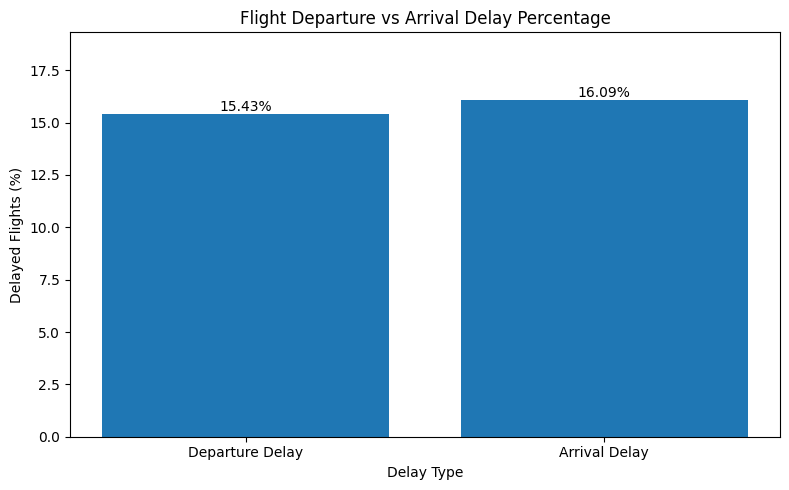

In [18]:


# Compare departure and arrival delay percentages
delay_types = ['Departure Delay', 'Arrival Delay']
delay_percentages = [departure_percentage, arrival_percentage]

plt.figure(figsize=(8, 5))
bars = plt.bar(delay_types, delay_percentages)

plt.title('Flight Departure vs Arrival Delay Percentage')
plt.xlabel('Delay Type')
plt.ylabel('Delayed Flights (%)')
plt.ylim(0, max(delay_percentages) * 1.2)

# Display percentage values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.2f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


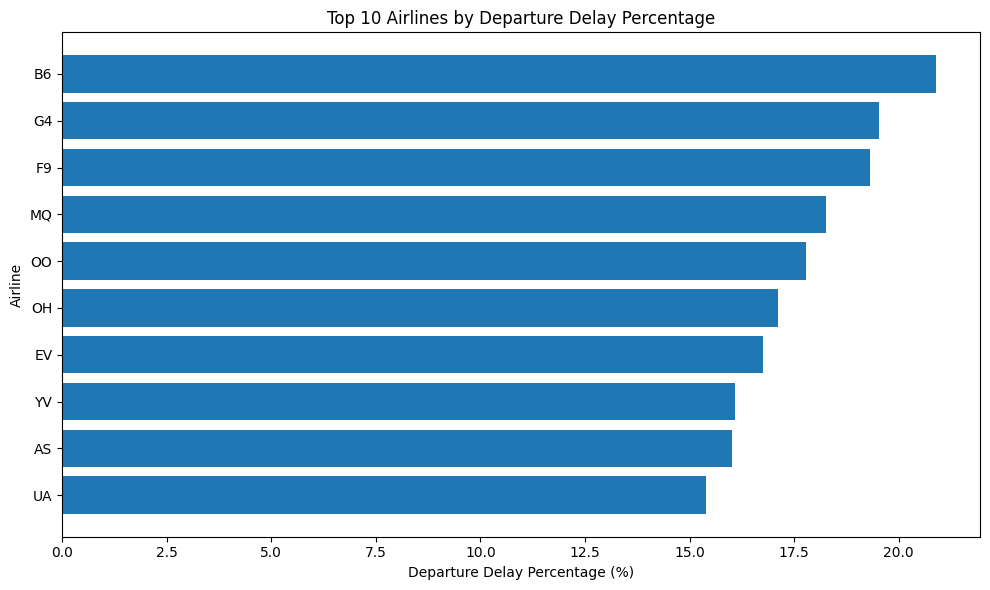

In [19]:


# Select the 10 airlines with the highest departure delay percentages
top_airlines = airline_delays.head(10).sort_values(
    'Delay_Percentage', ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_airlines.index,
    top_airlines['Delay_Percentage']
)

plt.title('Top 10 Airlines by Departure Delay Percentage')
plt.xlabel('Departure Delay Percentage (%)')
plt.ylabel('Airline')

plt.tight_layout()
plt.show()


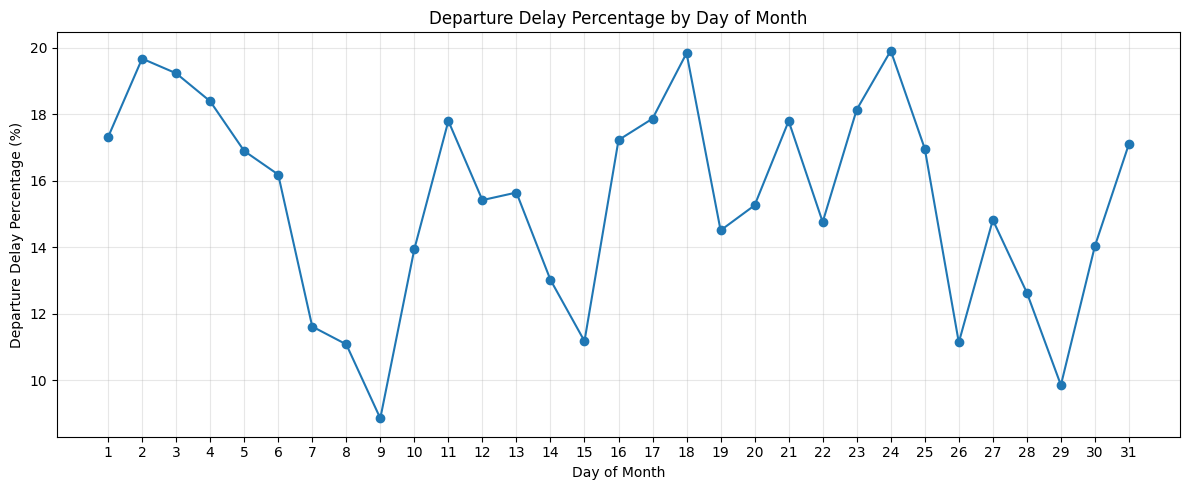

In [20]:

# Monthly flight delay analysis

monthly_delays = analysis_df.groupby('DAY_OF_MONTH').agg(
    Total_Flights=('DEP_DEL15', 'count'),
    Delayed_Flights=('DEP_DEL15', 'sum')
)

monthly_delays['Delay_Percentage'] = (
    monthly_delays['Delayed_Flights']
    / monthly_delays['Total_Flights'] * 100
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_delays.index,
    monthly_delays['Delay_Percentage'],
    marker='o'
)

plt.title('Departure Delay Percentage by Day of Month')
plt.xlabel('Day of Month')
plt.ylabel('Departure Delay Percentage (%)')
plt.xticks(range(1, 32))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


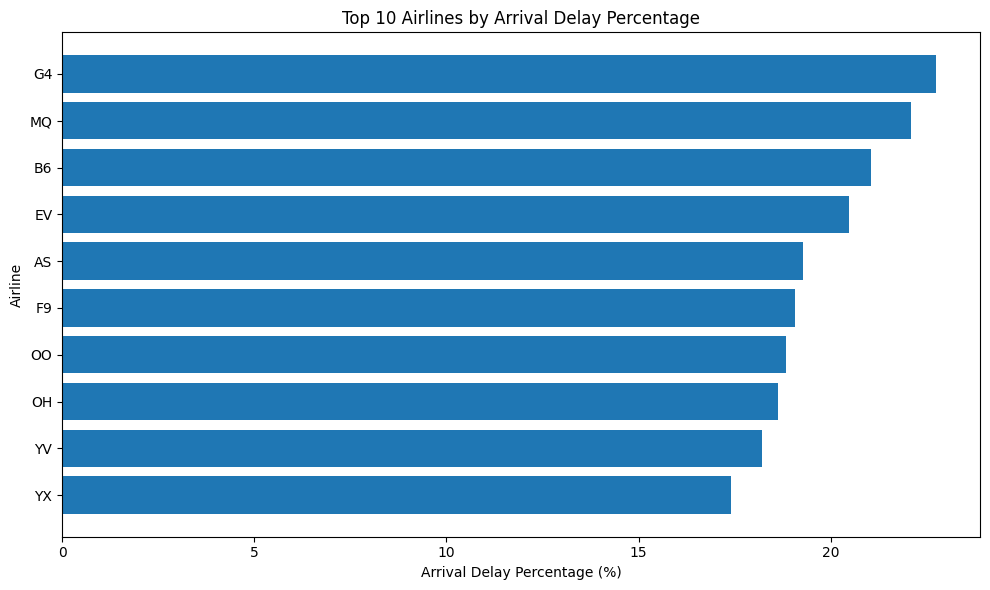

In [21]:

# Top 10 airlines by arrival delay percentage

top_arrival_airlines = arrival_airline_delays.head(10).sort_values(
    'Arrival_Delay_Percentage', ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_arrival_airlines.index,
    top_arrival_airlines['Arrival_Delay_Percentage']
)

plt.title('Top 10 Airlines by Arrival Delay Percentage')
plt.xlabel('Arrival Delay Percentage (%)')
plt.ylabel('Airline')

plt.tight_layout()
plt.show()


Departure delays by day of the week:


,Total_Flights,Delayed_Flights,Delay_Percentage
DAY_OF_WEEK,,,
1,158477,24610.0,15.53
2,165720,21777.0,13.14
3,189630,26277.0,13.86
4,199476,32908.0,16.50
5,179378,29226.0,16.29
6,123680,21169.0,17.12
7,148870,23785.0,15.98


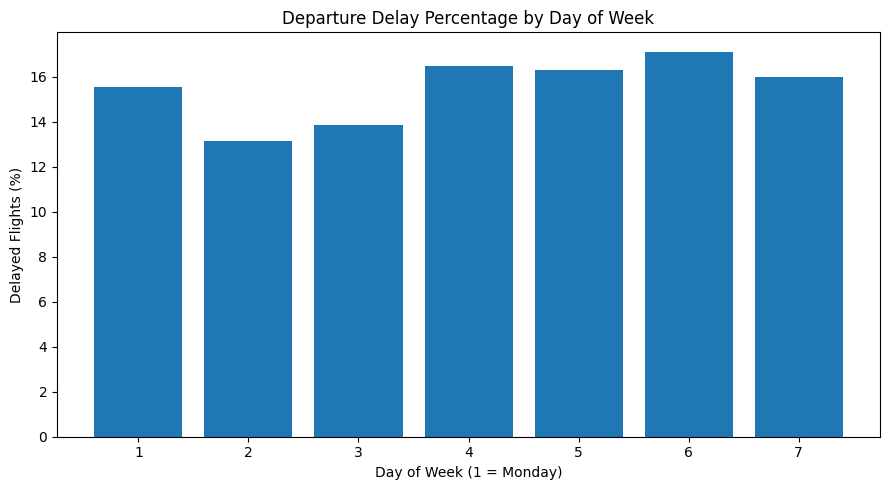

In [22]:

# Departure delay analysis by day of the week

weekday_delays = analysis_df.groupby('DAY_OF_WEEK').agg(
    Total_Flights=('DEP_DEL15', 'count'),
    Delayed_Flights=('DEP_DEL15', 'sum')
)

weekday_delays['Delay_Percentage'] = (
    weekday_delays['Delayed_Flights']
    / weekday_delays['Total_Flights'] * 100
)

print("Departure delays by day of the week:")
display(weekday_delays.round(2))

# Plot the results
plt.figure(figsize=(9, 5))

plt.bar(
    weekday_delays.index,
    weekday_delays['Delay_Percentage']
)

plt.title('Departure Delay Percentage by Day of Week')
plt.xlabel('Day of Week (1 = Monday)')
plt.ylabel('Delayed Flights (%)')
plt.xticks(range(1, 8))
plt.tight_layout()
plt.show()


Top 10 origin airports by departure delay percentage:


,Total_Flights,Delayed_Flights,Delay_Percentage
ORIGIN,,,
ASE,1632,565.0,34.62
MDW,11449,2702.0,23.60
FAR,1009,225.0,22.30
ORD,48102,10639.0,22.12
BTV,1281,271.0,21.16
EWR,21557,4533.0,21.03
LGA,27066,5595.0,20.67
SBN,1057,211.0,19.96
EYW,1238,246.0,19.87


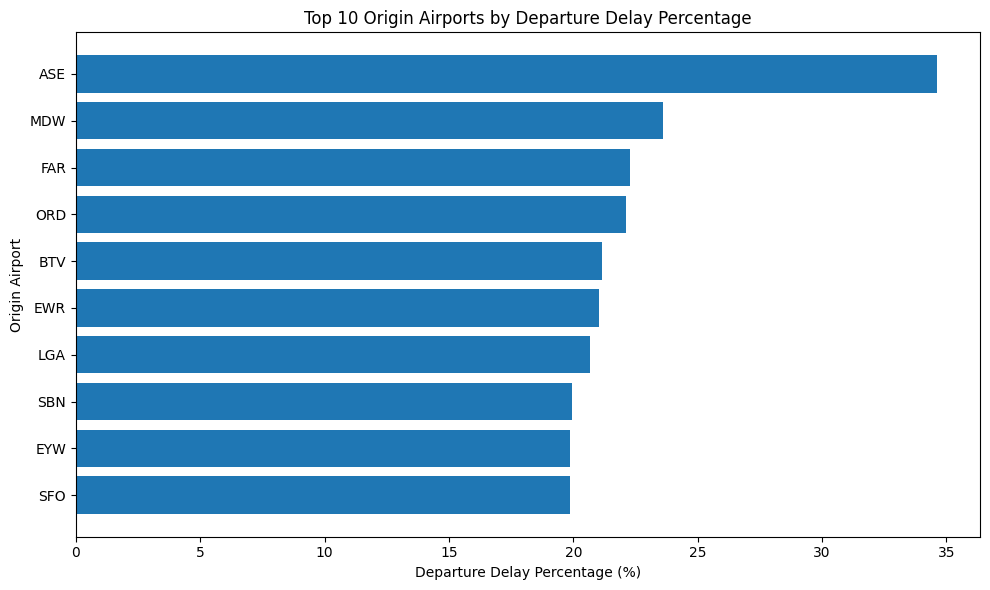

In [23]:

# Departure delay analysis by origin airport

airport_delays = analysis_df.groupby('ORIGIN').agg(
    Total_Flights=('DEP_DEL15', 'count'),
    Delayed_Flights=('DEP_DEL15', 'sum')
)

airport_delays['Delay_Percentage'] = (
    airport_delays['Delayed_Flights']
    / airport_delays['Total_Flights'] * 100
)

# Include airports with at least 1,000 flights for a fairer comparison
airport_delays = airport_delays[
    airport_delays['Total_Flights'] >= 1000
]

airport_delays = airport_delays.sort_values(
    'Delay_Percentage', ascending=False
)

print("Top 10 origin airports by departure delay percentage:")
display(airport_delays.head(10).round(2))

# Visualize the top 10
top_airports = airport_delays.head(10).sort_values(
    'Delay_Percentage', ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_airports.index,
    top_airports['Delay_Percentage']
)

plt.title('Top 10 Origin Airports by Departure Delay Percentage')
plt.xlabel('Departure Delay Percentage (%)')
plt.ylabel('Origin Airport')
plt.tight_layout()
plt.show()


Departure delays by scheduled time block:


,Total_Flights,Delayed_Flights,Delay_Percentage
DEP_TIME_BLK,,,
0001-0559,31413,2485.0,7.91
0600-0659,84358,5436.0,6.44
0700-0759,77553,6335.0,8.17
0800-0859,76889,7670.0,9.98
0900-0959,69828,8302.0,11.89
1000-1059,70303,10170.0,14.47
1100-1159,73471,10913.0,14.85
1200-1259,73476,11818.0,16.08
1300-1359,66655,11466.0,17.20


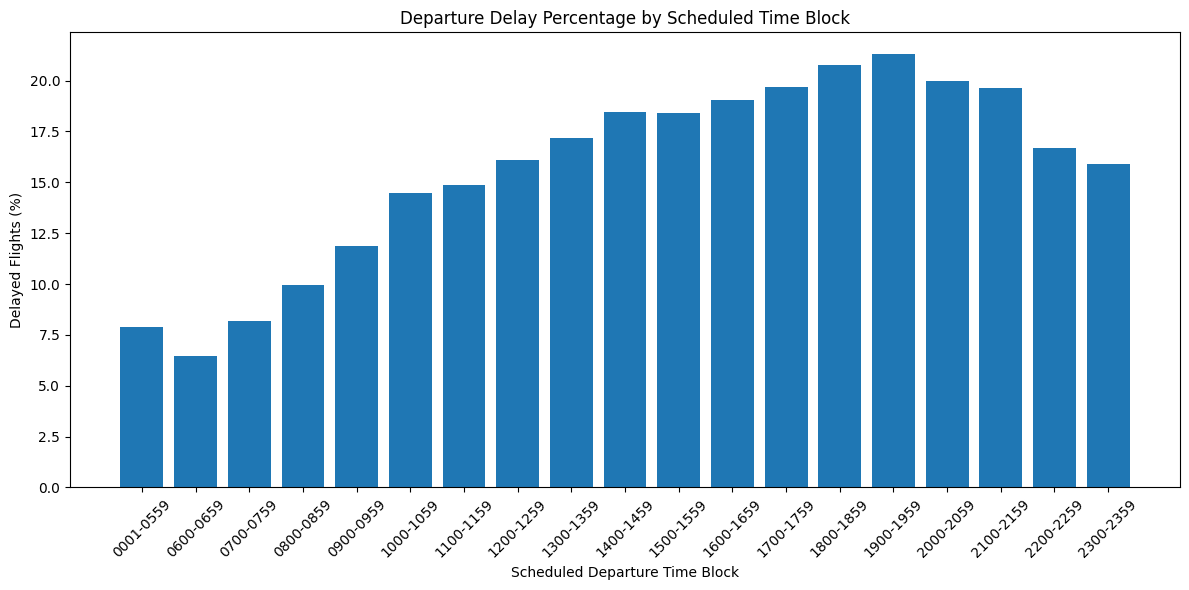

In [24]:


# Keep valid departure delay records
time_df = analysis_df.dropna(
    subset=['DEP_TIME_BLK', 'DEP_DEL15']
).copy()

# Calculate delay percentage for each scheduled departure time block
time_delays = time_df.groupby('DEP_TIME_BLK').agg(
    Total_Flights=('DEP_DEL15', 'count'),
    Delayed_Flights=('DEP_DEL15', 'sum')
)

time_delays['Delay_Percentage'] = (
    time_delays['Delayed_Flights']
    / time_delays['Total_Flights'] * 100
)

print("Departure delays by scheduled time block:")
display(time_delays.round(2))

# Visualize the results
# Matplotlib bar chart avoids Seaborn compatibility issues with empty or unusual categories.
plt.figure(figsize=(12, 6))

plt.bar(
    time_delays.index.astype(str),
    time_delays['Delay_Percentage']
)

plt.title('Departure Delay Percentage by Scheduled Time Block')
plt.xlabel('Scheduled Departure Time Block')
plt.ylabel('Delayed Flights (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


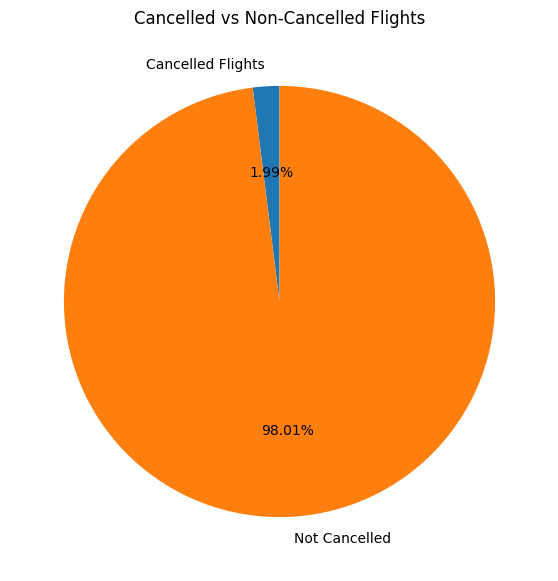

In [25]:

cancelled = (df['CANCELLED'] == 1).sum()
not_cancelled = (df['CANCELLED'] == 0).sum()

labels = ['Cancelled Flights', 'Not Cancelled']
sizes = [cancelled, not_cancelled]

plt.figure(figsize=(7, 7))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Cancelled vs Non-Cancelled Flights')
plt.show()

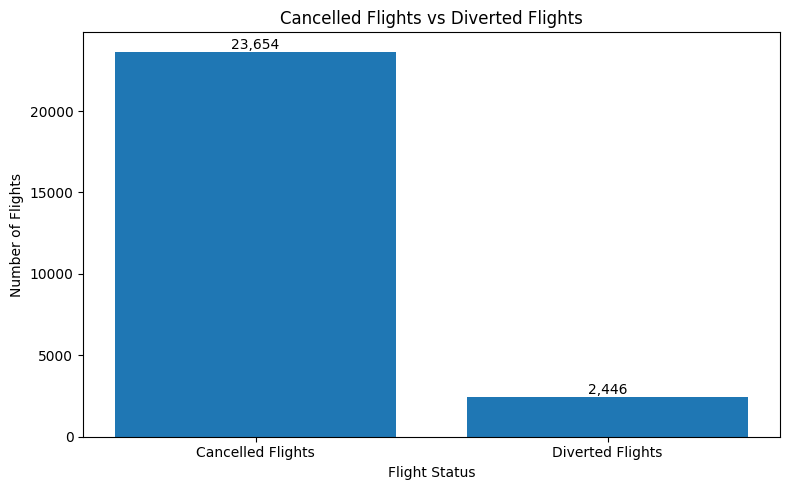

In [26]:

cancelled = (df['CANCELLED'] == 1).sum()
diverted = (df['DIVERTED'] == 1).sum()

categories = ['Cancelled Flights', 'Diverted Flights']
counts = [cancelled, diverted]

plt.figure(figsize=(8, 5))
bars = plt.bar(categories, counts)

plt.title('Cancelled Flights vs Diverted Flights')
plt.xlabel('Flight Status')
plt.ylabel('Number of Flights')

# Display the count above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{int(height):,}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

# 9. Flight Delay Analysis Dashboard

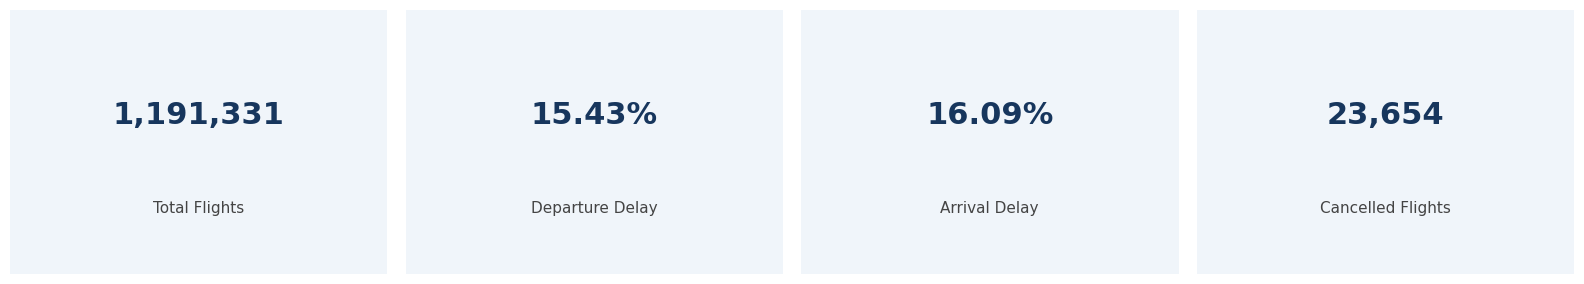

Diverted flights: 2,446


In [27]:
# STEP 1: DASHBOARD TITLE AND KPI CARDS

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

# Dashboard style
sns.set_theme(style="whitegrid")

# Use the full dataset for total flights and disruptions.
# Use valid delay records for departure and arrival delay percentages.
total_flights = len(df)
cancelled_flights = (df["CANCELLED"] == 1).sum()
diverted_flights = (df["DIVERTED"] == 1).sum()

departure_percentage = (
    (analysis_df["DEP_DEL15"] == 1).sum()
    / analysis_df["DEP_DEL15"].notna().sum()
) * 100

arrival_percentage = (
    (analysis_df["ARR_DEL15"] == 1).sum()
    / analysis_df["ARR_DEL15"].notna().sum()
) * 100

# Display dashboard title
display(HTML("""
<div style="
    background-color:#17365D;
    color:white;
    padding:22px;
    border-radius:10px;
    text-align:center;
    margin-bottom:15px;">
    <h1 style="margin:0;">✈ Flight Delay Analysis Dashboard</h1>
    <p style="margin:8px 0 0 0;">
        January 2019 and January 2020 | Flight Delay Analysis Project
    </p>
</div>
"""))

# Create four KPI cards
metrics = [
    ("Total Flights", f"{total_flights:,}"),
    ("Departure Delay", f"{departure_percentage:.2f}%"),
    ("Arrival Delay", f"{arrival_percentage:.2f}%"),
    ("Cancelled Flights", f"{cancelled_flights:,}")
]

fig, axes = plt.subplots(1, 4, figsize=(16, 3))

for ax, (label, value) in zip(axes, metrics):
    ax.set_facecolor("#F0F5FA")
    ax.text(
        0.5, 0.60, value,
        ha="center", va="center",
        fontsize=22, fontweight="bold",
        color="#17365D"
    )
    ax.text(
        0.5, 0.25, label,
        ha="center", va="center",
        fontsize=11, color="#444444"
    )
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

plt.tight_layout()
plt.show()

print(f"Diverted flights: {diverted_flights:,}")

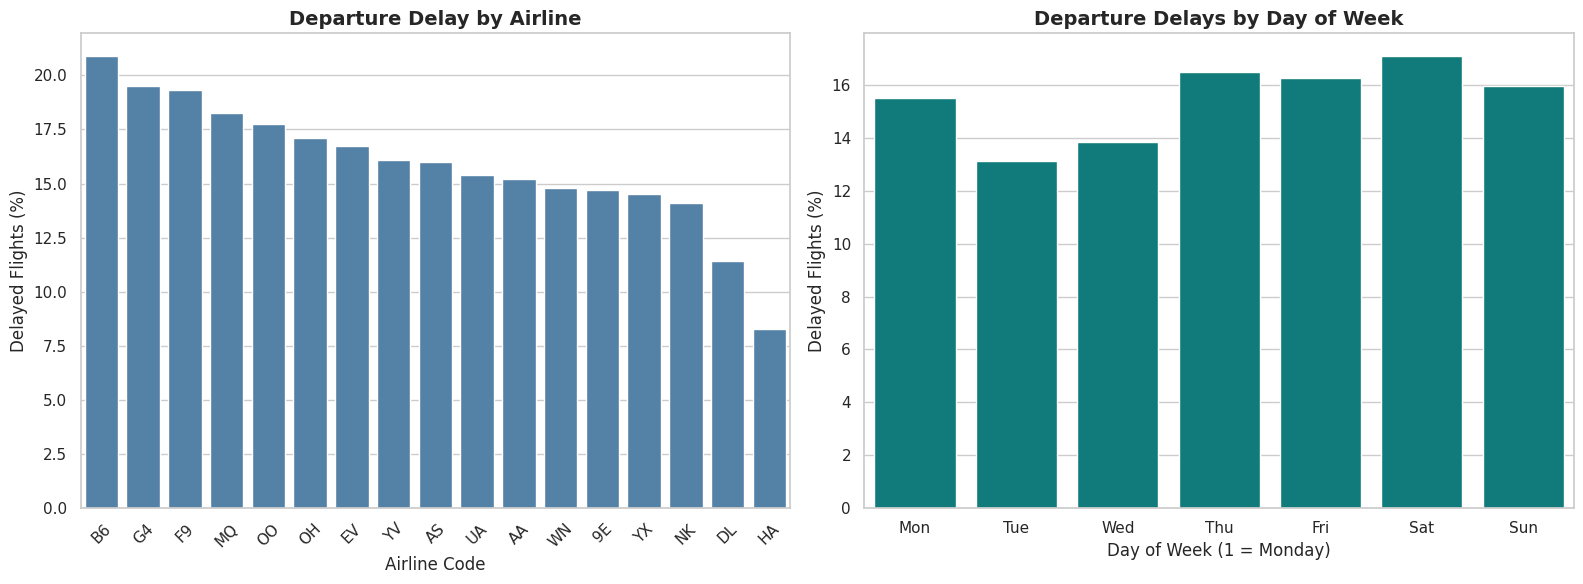

In [28]:
# STEP 2: AIRLINE DELAYS AND WEEKDAY ANALYSIS

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Departure delay percentage by airline
airline_delays = (
    analysis_df.groupby("OP_UNIQUE_CARRIER")
    .agg(
        Total_Flights=("DEP_DEL15", "count"),
        Delayed_Flights=("DEP_DEL15", lambda x: (x == 1).sum())
    )
)

airline_delays["Delay_Percentage"] = (
    airline_delays["Delayed_Flights"]
    / airline_delays["Total_Flights"] * 100
)

airline_delays = airline_delays.sort_values(
    "Delay_Percentage", ascending=False
)

sns.barplot(
    data=airline_delays.reset_index(),
    x="OP_UNIQUE_CARRIER",
    y="Delay_Percentage",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Departure Delay by Airline", fontsize=14, weight="bold")
axes[0].set_xlabel("Airline Code")
axes[0].set_ylabel("Delayed Flights (%)")
axes[0].tick_params(axis="x", rotation=45)

# Chart 2: Departure delay percentage by day of the week
weekday_delays = (
    analysis_df.groupby("DAY_OF_WEEK")["DEP_DEL15"]
    .agg(
        Total_Flights="count",
        Delayed_Flights=lambda x: (x == 1).sum()
    )
)

weekday_delays["Delay_Percentage"] = (
    weekday_delays["Delayed_Flights"]
    / weekday_delays["Total_Flights"] * 100
)

sns.barplot(
    x=weekday_delays.index,
    y=weekday_delays["Delay_Percentage"],
    ax=axes[1],
    color="darkcyan"
)

axes[1].set_title("Departure Delays by Day of Week", fontsize=14, weight="bold")
axes[1].set_xlabel("Day of Week (1 = Monday)")
axes[1].set_ylabel("Delayed Flights (%)")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

plt.tight_layout()
plt.show()

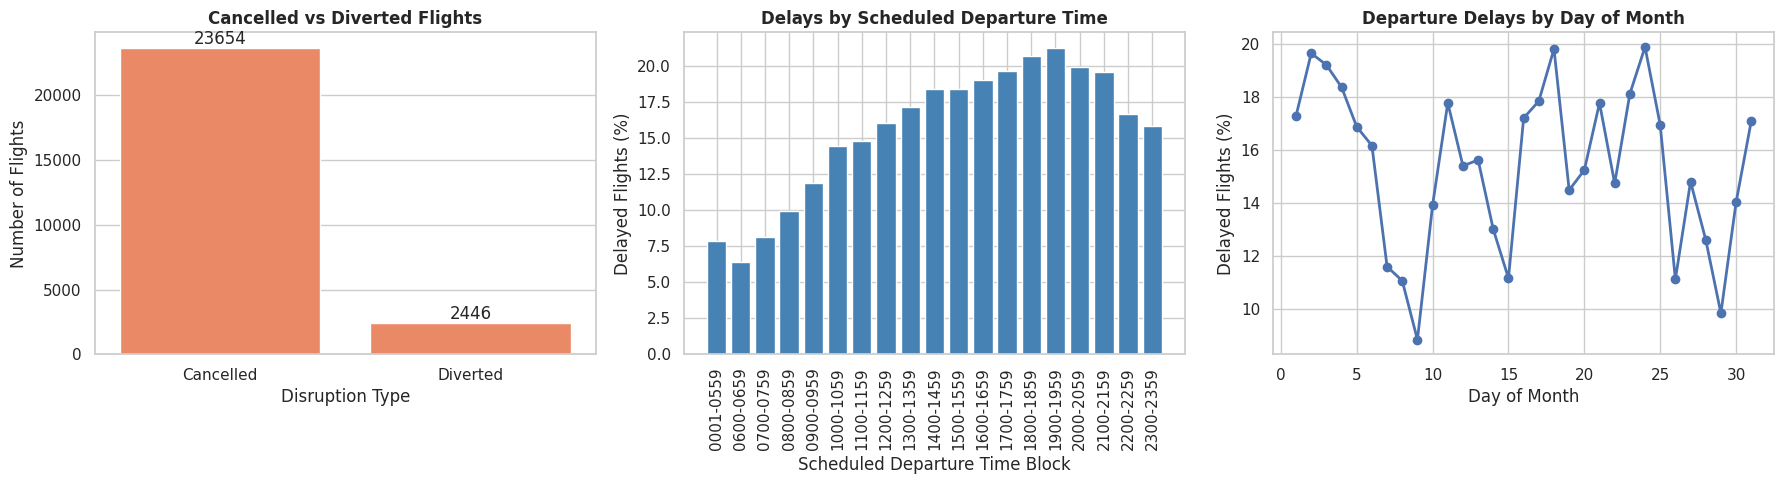

In [29]:
# STEP 3: FLIGHT DISRUPTIONS AND DEPARTURE-TIME ANALYSIS

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Cancelled vs diverted flights
disruptions = pd.Series({
    "Cancelled": (df["CANCELLED"] == 1).sum(),
    "Diverted": (df["DIVERTED"] == 1).sum()
})

sns.barplot(
    x=disruptions.index,
    y=disruptions.values,
    ax=axes[0],
    color="coral"
)

axes[0].set_title("Cancelled vs Diverted Flights", weight="bold")
axes[0].set_xlabel("Disruption Type")
axes[0].set_ylabel("Number of Flights")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f")

# Chart 2: Departure delays by scheduled time block
time_delays = (
    analysis_df.groupby("DEP_TIME_BLK")["DEP_DEL15"]
    .agg(
        Total_Flights="count",
        Delayed_Flights=lambda x: (x == 1).sum()
    )
)

time_delays["Delay_Percentage"] = (
    time_delays["Delayed_Flights"]
    / time_delays["Total_Flights"] * 100
)

time_delays = time_delays.sort_index()

axes[1].bar(
    time_delays.index.astype(str),
    time_delays["Delay_Percentage"],
    color="steelblue"
)

axes[1].set_title("Delays by Scheduled Departure Time", weight="bold")
axes[1].set_xlabel("Scheduled Departure Time Block")
axes[1].set_ylabel("Delayed Flights (%)")
axes[1].tick_params(axis="x", rotation=90)

# Chart 3: Departure delay percentage by day of month
daily_delays = (
    analysis_df.groupby("DAY_OF_MONTH")["DEP_DEL15"]
    .agg(
        Total_Flights="count",
        Delayed_Flights=lambda x: (x == 1).sum()
    )
)

daily_delays["Delay_Percentage"] = (
    daily_delays["Delayed_Flights"]
    / daily_delays["Total_Flights"] * 100
)

axes[2].plot(
    daily_delays.index,
    daily_delays["Delay_Percentage"],
    marker="o",
    linewidth=2
)

axes[2].set_title("Departure Delays by Day of Month", weight="bold")
axes[2].set_xlabel("Day of Month")
axes[2].set_ylabel("Delayed Flights (%)")

plt.tight_layout()
plt.show()

In [38]:

# STEP 4: PROFESSIONAL DASHBOARD INSIGHTS

from IPython.display import display, HTML

# Calculate the highest-delay airline
worst_airline = airline_delays["Delay_Percentage"].idxmax()
worst_airline_rate = airline_delays["Delay_Percentage"].max()

# Calculate the weekday with the highest delay percentage
worst_weekday = weekday_delays["Delay_Percentage"].idxmax()
worst_weekday_rate = weekday_delays["Delay_Percentage"].max()

# Calculate the departure-time block with the highest delay percentage
worst_time = time_delays["Delay_Percentage"].idxmax()
worst_time_rate = time_delays["Delay_Percentage"].max()

display(HTML(f"""
<div style="
    background-color:#172B4D;
    color:#FFFFFF;
    padding:28px;
    border-radius:14px;
    font-family:Arial, sans-serif;
    line-height:1.8;
    margin-top:20px;
    border:1px solid #344563;">

    <h2 style="
        color:#7DD3FC;
        font-size:26px;
        margin-top:0;
        border-bottom:2px solid #38BDF8;
        padding-bottom:12px;">
        ✈ KEY INSIGHTS
    </h2>

    <p><b style="color:#7DD3FC;">Departure delays:</b>
    {departure_percentage:.2f}% of flights with recorded departure-delay
    status were delayed by 15 minutes or more.</p>

    <p><b style="color:#7DD3FC;">Arrival delays:</b>
    {arrival_percentage:.2f}% of flights with recorded arrival-delay
    status were delayed by 15 minutes or more.</p>

    <p><b style="color:#7DD3FC;">Airline comparison:</b>
    Airline {worst_airline} had the highest observed departure-delay
    percentage ({worst_airline_rate:.2f}%).</p>

    <p><b style="color:#7DD3FC;">Weekday comparison:</b>
    Day {worst_weekday} had the highest observed departure-delay
    percentage ({worst_weekday_rate:.2f}%).</p>

    <p><b style="color:#7DD3FC;">Departure time:</b>
    Time block {worst_time} had the highest observed departure-delay
    percentage ({worst_time_rate:.2f}%).</p>

    <p><b style="color:#7DD3FC;">Flight disruptions:</b>
    {cancelled_flights:,} flights were cancelled and
    {diverted_flights:,} were diverted.</p>

    <p style="
        color:#BAE6FD;
        font-size:13px;
        margin-bottom:0;
        border-top:1px solid #475569;
        padding-top:12px;">
        Flight Delay Analysis Project | Python, Pandas,
        Matplotlib and Seaborn
    </p>
</div>
"""))


## 8. Summary of Results

In [33]:

summary = pd.DataFrame({
    'Metric': [
        'Total Flights',
        'Departure Delay Percentage',
        'Arrival Delay Percentage',
        'Cancelled Flights',
        'Cancellation Percentage',
        'Diverted Flights',
        'Diversion Percentage'
    ],
    'Value': [
        len(df),
        round(departure_percentage, 2),
        round(arrival_percentage, 2),
        cancelled_flights,
        round(cancellation_percentage, 2),
        diverted_flights,
        round(diversion_percentage, 2)
    ]
})

display(summary)

,Metric,Value
0,Total Flights,1191331.00
1,Departure Delay Percentage,15.43
2,Arrival Delay Percentage,16.09
3,Cancelled Flights,23654.00
4,Cancellation Percentage,1.99
5,Diverted Flights,2446.00
6,Diversion Percentage,0.21


## Conclusion

This project analyzed flight delay data from January 2019 and January 2020 using Python. Pandas was used for data processing, while Matplotlib and Seaborn were used to create visualizations.

The combined dataset contained 1,191,331 flight records. The analysis found that 15.43% of flights had departure delays and 16.09% had arrival delays. In addition, 23,654 flights were cancelled, representing 1.99% of all records, while 2,446 flights were diverted, representing 0.21%.

The project also explored delay percentages by airline, day of the month, day of the week, origin airport, and scheduled departure time block. These visualizations help identify patterns in flight operations and compare delays across different categories.

Overall, this project demonstrates how Python data analysis and visualization libraries can be used to explore a large real-world dataset and communicate useful findings clearly.